Задача 1, Вариант 3

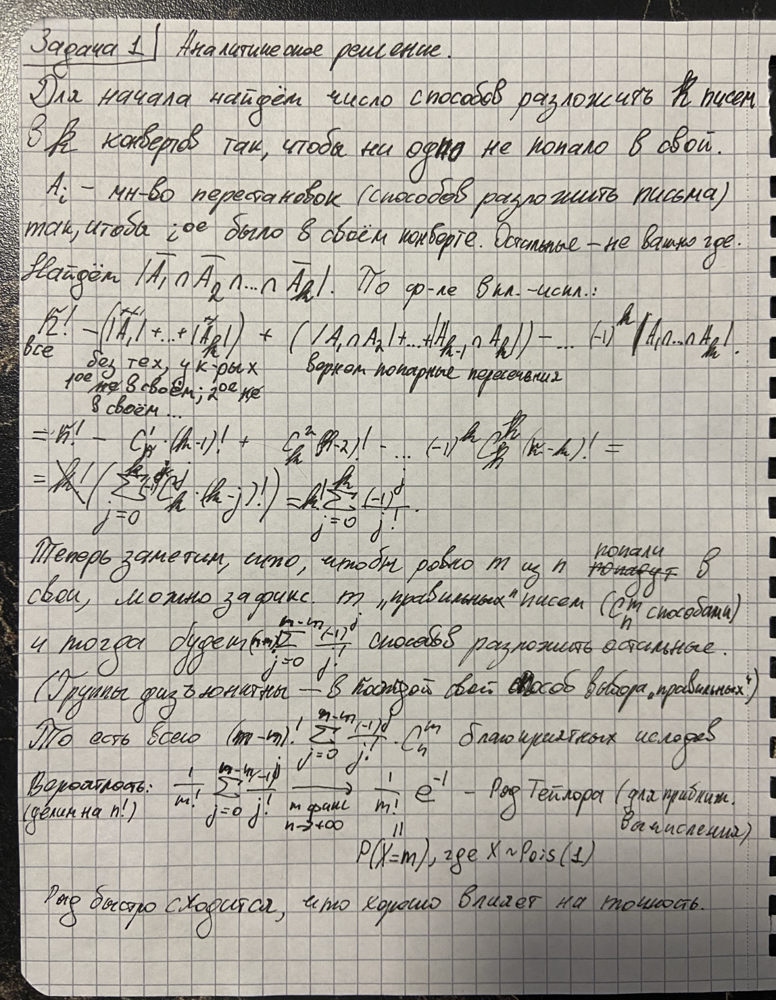

In [1]:
import math
import numpy as np

def exact_probability(n, m):
    if m > n or m < 0:
        return 0.0

    s = sum((-1)**j / math.factorial(j) for j in range(n - m + 1))
    return s / math.factorial(m)


def approx_probability(m):
    return math.exp(-1) / math.factorial(m)


def run_simulations(n, m, num_simulations):
    successful_simulations = 0
    for _ in range(num_simulations):
        shuffled_letters = np.random.permutation(n)
        n_matches = np.sum(shuffled_letters == np.arange(n))

        if n_matches == m:
            successful_simulations += 1

    return successful_simulations / num_simulations


test_cases = [
    (5, 2),
    (10, 0),
    (100, 3),
    (100, 5)
]

print(f"{'N':<5} | {'M':<4} | {'Симуляции':<10} | {'Точная':<12} | {'Приближ.':<18} | {'Эмпирич.':<15}")
print("-" * 80)

for n, m in test_cases:
    exact = exact_probability(n, m)
    approx = approx_probability(m)
    sim = run_simulations(n, m, 100000)
    print(f"{n:<5} | {m:<4} | {100000:<10} | {exact:<12.6f} | {approx:<18.6f} | {sim:<15.6f}")
    

N     | M    | Симуляции  | Точная       | Приближ.           | Эмпирич.       
--------------------------------------------------------------------------------
5     | 2    | 100000     | 0.166667     | 0.183940           | 0.165630       
10    | 0    | 100000     | 0.367879     | 0.367879           | 0.365260       
100   | 3    | 100000     | 0.061313     | 0.061313           | 0.062140       
100   | 5    | 100000     | 0.003066     | 0.003066           | 0.003210       


1) Опыт точнее приближенного вычисления (малое N - точность приближенного низкая - т. к. в точной вероятности набежало мало слагаемых в ряде Тейлора)
2) Видимо, достаточно большое N и все три варианта сопоставимы
3) Опыт начинает сдавать - недостаточно симуляций для 100 конвертов
4) То же, что и в 3.

Задача 2, Вариант 3

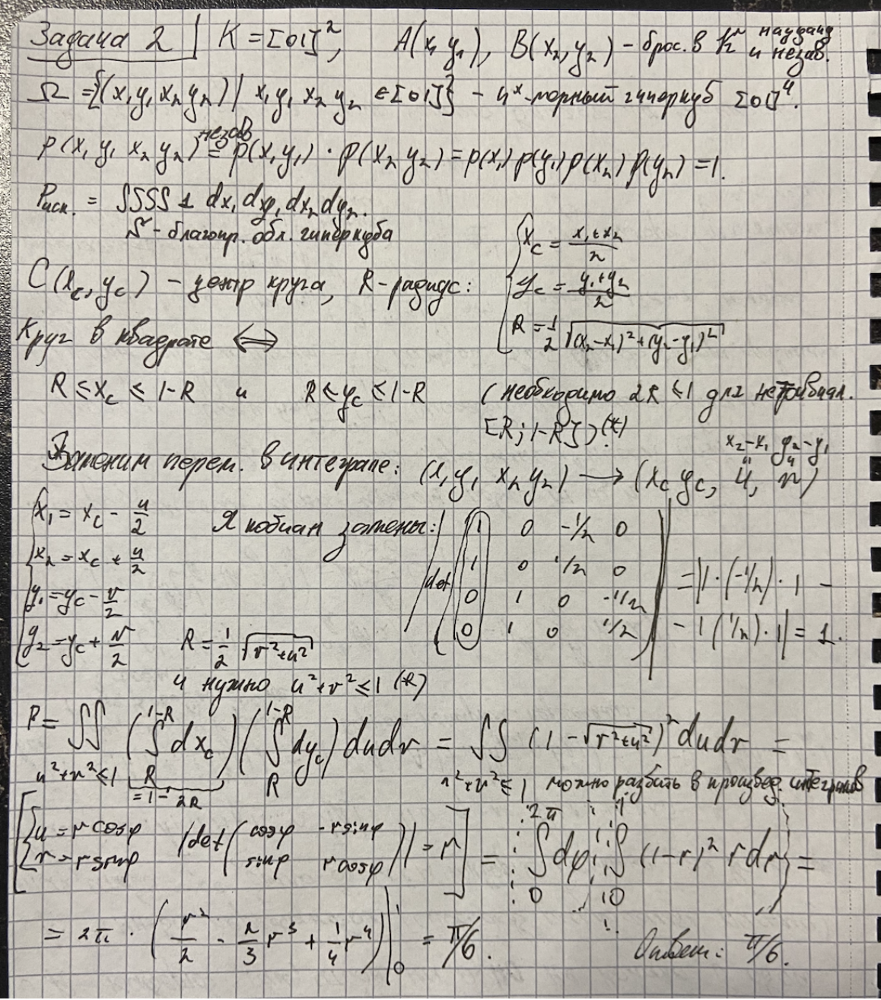

In [2]:
def run_simulations2(num_simulations):
    x1 = np.random.rand(num_simulations)
    y1 = np.random.rand(num_simulations)
    x2 = np.random.rand(num_simulations)
    y2 = np.random.rand(num_simulations)

    x_c = (x1 + x2) / 2
    y_c = (y1 + y2) / 2

    R = 1/2 * np.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

    valid_x = (x_c >= R) & (x_c <= 1 - R)
    valid_y = (y_c >= R) & (y_c <= 1 - R)

    successes = valid_x & valid_y

    return np.sum(successes) / num_simulations


test_cases = [10**k for k in range(5, 9)]
exact_prob = np.pi / 6

print(f"Точная теоретическая вероятность (pi/6) : {exact_prob:.6f}\n")
print(f"{'Симуляции':<12} | {'Эмпирическая':<15} | {'Абс. ошибка':<15}")
print("-" * 47)

for num_simulations in test_cases:
    emp_prob = run_simulations2(num_simulations)
    error = abs(exact_prob - emp_prob)
    print(f"{num_simulations:<12} | {emp_prob:<15.6f} | {error:<15.6f}")
    

Точная теоретическая вероятность (pi/6) : 0.523599

Симуляции    | Эмпирическая    | Абс. ошибка    
-----------------------------------------------
100000       | 0.524040        | 0.000441       
1000000      | 0.523873        | 0.000274       
10000000     | 0.523786        | 0.000187       
100000000    | 0.523516        | 0.000083       


Видно, что опыт дает неплохие результаты, имеющие тенденцию к улучшению точности с ростом числа запусков симуляции.

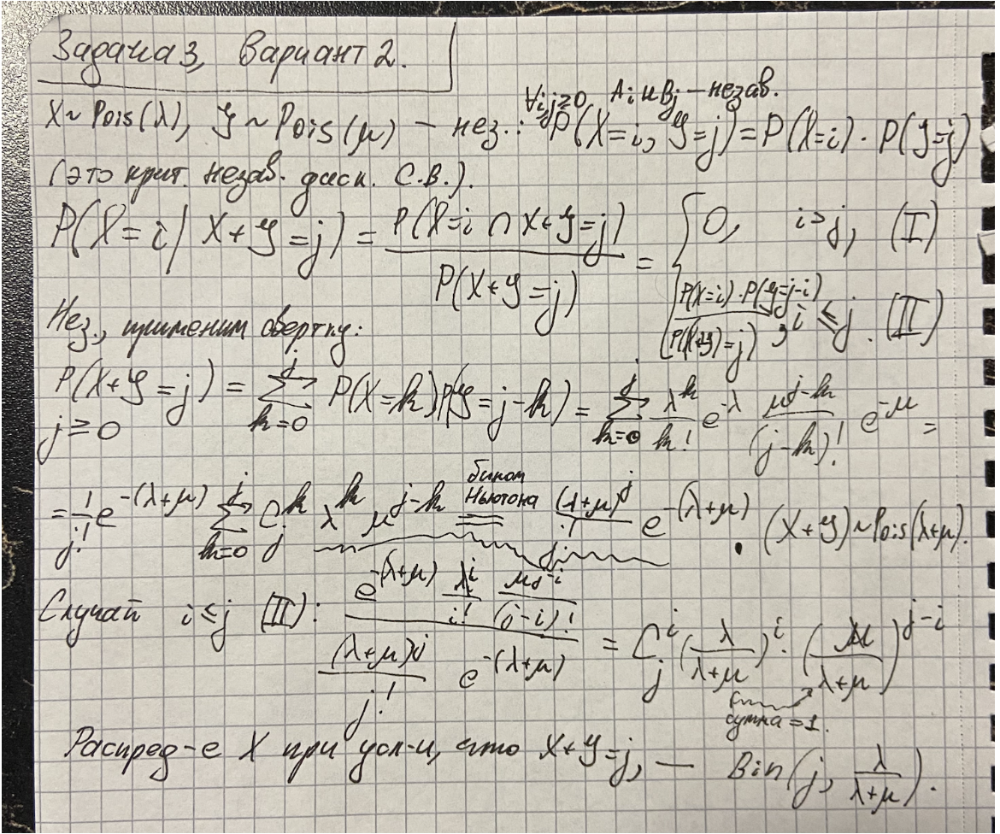

Задача 4, Вариант 5

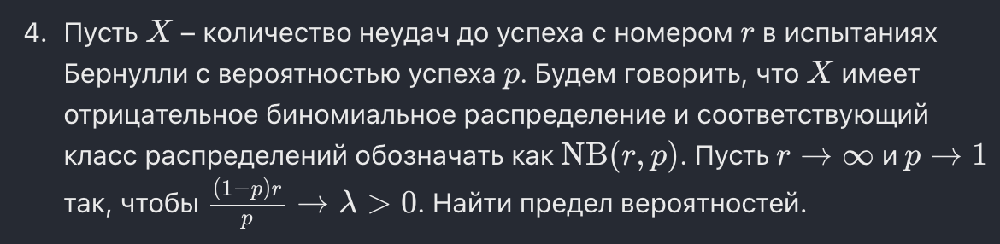

Lambda   | r     | p        | Макс. погрешность max|P_NB - P_Pois| (среди нескольких первых k)
-----------------------------------------------------------------
1.0      | 2     | 0.6667   | 0.076565
1.0      | 10    | 0.9091   | 0.017664
1.0      | 50    | 0.9804   | 0.003648
1.0      | 250   | 0.9960   | 0.000735
5.0      | 2     | 0.2857   | 0.084397
5.0      | 10    | 0.6667   | 0.032596
5.0      | 50    | 0.9091   | 0.008191
5.0      | 250   | 0.9804   | 0.001730
10.0     | 2     | 0.1667   | 0.075761
10.0     | 10    | 0.5000   | 0.037012
10.0     | 50    | 0.8333   | 0.010932
10.0     | 250   | 0.9615   | 0.002431


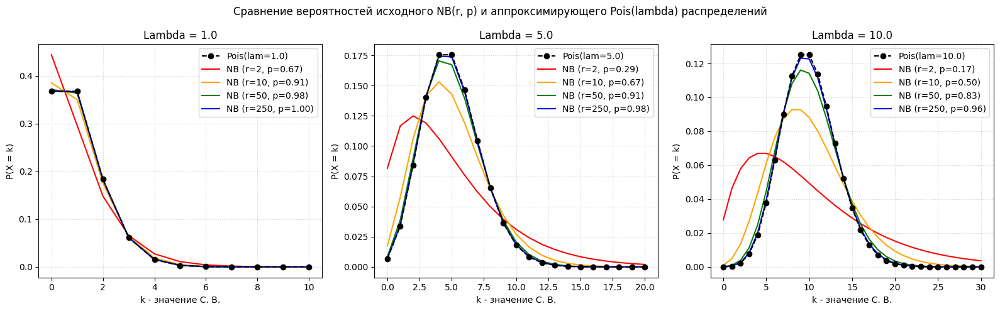

In [3]:
import matplotlib.pyplot as plt
from scipy.stats import poisson, nbinom

lambdas = [1.0, 5.0, 10.0]
rs = [2, 10, 50, 250]
ks = [10, 20, 30]
colors = ['red', 'orange', 'green', 'blue']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Сравнение вероятностей исходного NB(r, p) и аппроксимирующего Pois(lambda) распределений')

print(f"{'Lambda':<8} | {'r':<5} | {'p':<8} | {'Макс. погрешность max|P_NB - P_Pois| (среди нескольких первых k)'}")
print("-" * 65)

for idx, lam in enumerate(lambdas):
    ax = axes[idx]

    max_k = ks[idx]
    k_vals = np.arange(max_k + 1)
    
    pois_pmf = poisson.pmf(k_vals, lam)
    ax.plot(k_vals, pois_pmf, 'k--o', label=f"Pois(lam={lam})", zorder=100)

    for r, color in zip(rs, colors):
        # r * (1 - p) / p = lambda => p = r / (r + lambda) - подбираем p под фикс. lambda
        p = r / (r + lam)
        nb_pmf = nbinom.pmf(k_vals, r, p)

        max_err = np.max(np.abs(nb_pmf - pois_pmf))
        print(f"{lam:<8.1f} | {r:<5} | {p:<8.4f} | {max_err:.6f}")

        ax.plot(k_vals, nb_pmf, color=color, label=f'NB (r={r}, p={p:.2f})')

    ax.set_title(f'Lambda = {lam}')
    ax.set_xlabel('k - значение С. В.')
    ax.set_ylabel('P(X = k)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()
    


Исследовал три различных значения lambda (три графика). Для каждого увеличивал r от 2 до 250 и менял p таким образом, чтобы r * (1 - p) / p = lambda. По мере роста r вероятности NB действительно сходятся к Pois. Синяя линия почти сливается с черной. Сходимость наблюдается при всех трех рассмотренных значениях lambda. Таблица в начале вывода содержит информацию о погрешностях при разных параметрах.

Задача 5. Вариант 2.

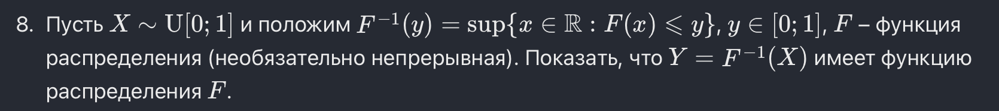
Но воспользуемся:
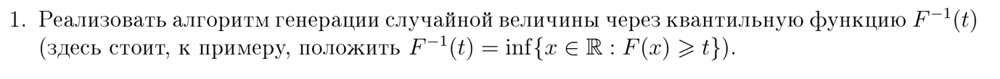

In [4]:
def quantile_function(t):
    res = np.empty_like(t)
    E = lambda x: 0.6 * np.exp(-2 * x)
    inv = lambda t_sub, C: -0.5 * np.log((C - t_sub) / 0.6)
    
    m = t <= 0.02; res[m] = -4.0
    m = (t > 0.02) & (t <= 0.05); res[m] = -2.0
    m = (t > 0.05) & (t <= 0.075); res[m] = -1.0
    
    m = (t > 0.075) & (t <= 0.12); res[m] = 0.0
    m = (t > 0.12) & (t < 0.72 - E(0.5)); res[m] = inv(t[m], 0.72)
    
    m = (t >= 0.72 - E(0.5)) & (t <= 0.755 - E(0.5)); res[m] = 0.5
    m = (t > 0.755 - E(0.5)) & (t < 0.755 - E(1.0)); res[m] = inv(t[m], 0.755)
    
    m = (t >= 0.755 - E(1.0)) & (t <= 0.81 - E(1.0)); res[m] = 1.0
    m = (t > 0.81 - E(1.0)) & (t < 0.81 - E(1.5)); res[m] = inv(t[m], 0.81)
    
    m = (t >= 0.81 - E(1.5)) & (t <= 0.85 - E(1.5)); res[m] = 1.5
    m = (t > 0.85 - E(1.5)) & (t < 0.85 - E(2.0)); res[m] = inv(t[m], 0.85)
    
    m = (t >= 0.85 - E(2.0)) & (t <= 0.9 - E(2.0)); res[m] = 2.0
    m = (t > 0.9 - E(2.0)) & (t < 0.9 - E(3.0)); res[m] = inv(t[m], 0.9)
    
    m = (t >= 0.9 - E(3.0)) & (t <= 0.945 - E(3.0)); res[m] = 3.0
    m = (t > 0.945 - E(3.0)) & (t < 0.945 - E(5.0)); res[m] = inv(t[m], 0.945)
    
    m = (t >= 0.945 - E(5.0)) & (t <= 1.0 - E(5.0)); res[m] = 5.0
    m = t > 1.0 - E(5.0); res[m] = inv(t[m], 1.0)
    
    return res



t_random = np.random.rand(10)
X_generated = quantile_function(t_random)

print("Сгенерированные значения t: ", np.round(t_random, 3))
print("Сгенерированные значения X: ", np.round(X_generated, 3))


Сгенерированные значения t:  [0.527 0.046 0.997 0.433 0.798 0.982 0.695 0.927 0.975 0.188]
Сгенерированные значения X:  [ 0.5   -2.     5.     0.369  1.5    5.     1.     3.     5.     0.06 ]


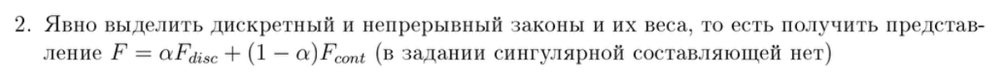

Скачком в точке x назовем F(x) - F(x-), если эта величина положительна.

В точке x = -4 скачок равен 0.02 - 0 = 0.02

В точке x = -2 скачок равен 0.03

В точке x = -1 скачок равен 0.025

В точке x = 0 скачок равен 0.045

В точке x = 0.5 скачок равен (0.755 - E(0.5)) - (0.72 - E(0.5)) = 0.035

В точке x = 1 скачок равен 0.055

В точке x = 1.5 скачок равен 0.04

В точке x = 2 скачок равен 0.05

В точке x = 3 скачок равен 0.045

В точке x = 5 скачок равен 0.055

Сумма составляет 0.4 - это и будет alpha. Теперь для каждого скачка в точке x_i разделим на 0.4 его величину и получим вероятность, что дискретная С. В. равна x_i. Например, P(X = -4) = 0.02 / 0.4 = 0.05.

F_disc(x) = sum(q[k] for k in range(10) if x[k] <= x)

x = [-4.0, -2.0, -1.0, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
q = [0.05, 0.075, 0.0625, 0.1125, 0.0875, 0.1375, 0.10, 0.125, 0.1125, 0.1375]

F(x) - 0.4F_disc(x) = I[x >= 0] * (0.6 - 0.6 * exp(-2x)) => F_cont(x) = (1 - exp(-2x))I[x >= 0] и включена с коэфф. 0.6. Это функция распределения для С. В., распределенной экспоненциально с параметром lambda = 2.




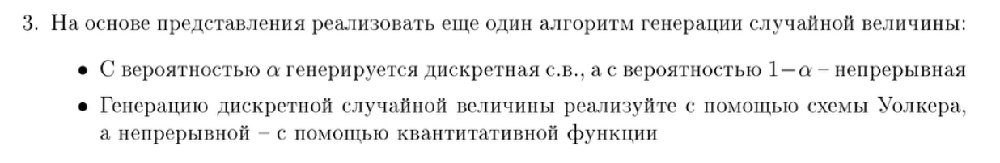

In [5]:
class WalkerAlias:
    def __init__(self, values, probabilities):
        self.values = np.array(values)
        self.n = len(probabilities)

        scaled_probs = np.array(probabilities) * self.n

        self.prob_table = np.zeros(self.n)
        self.alias_table = np.zeros(self.n, dtype=int)

        small = [i for i, p in enumerate(scaled_probs) if p < 1.0]
        large = [i for i, p in enumerate(scaled_probs) if p >= 1.0]

        while small and large:
            l = small.pop()
            g = large.pop()

            self.prob_table[l] = scaled_probs[l]
            self.alias_table[l] = g

            scaled_probs[g] = scaled_probs[g] - (1.0 - self.prob_table[l])

            if scaled_probs[g] < 1.0:
                small.append(g)
            else:
                large.append(g)

        while large:
            self.prob_table[large.pop()] = 1.0

        while small:
            self.prob_table[small.pop()] = 1.0


    def generate(self, size=1):
        i = np.floor(np.random.rand(size) * self.n).astype(int)
        u = np.random.rand(size)
        indices = np.where(u < self.prob_table[i], i, self.alias_table[i])
        return self.values[indices]


In [6]:
def quantile_cont(t):
    # F_cont(x) = 1 - exp(-2x) => x = -0.5 * ln(1 - t)
    return -0.5 * np.log(1 - t)

In [7]:
x_disc = [-4.0, -2.0, -1.0, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
q_probs = [0.05, 0.075, 0.0625, 0.1125, 0.0875, 0.1375, 0.10, 0.125, 0.1125, 0.1375]
walker = WalkerAlias(x_disc, q_probs)

def generate_mixed(size=1):
    alpha = 0.4

    u_mix = np.random.rand(size)
    is_discrete = u_mix < alpha

    num_disc = np.sum(is_discrete)
    num_cont = size - num_disc

    disc_samples = walker.generate(size=num_disc)
    
    u_cont = np.random.rand(num_cont)
    cont_samples = quantile_cont(u_cont)

    result = np.zeros(size)
    result[is_discrete] = disc_samples
    result[~is_discrete] = cont_samples

    return result


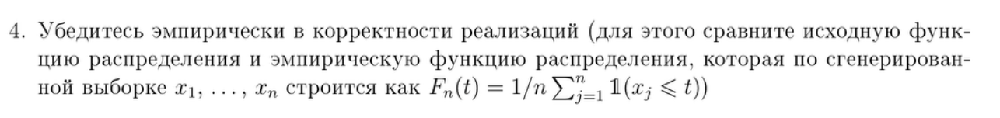

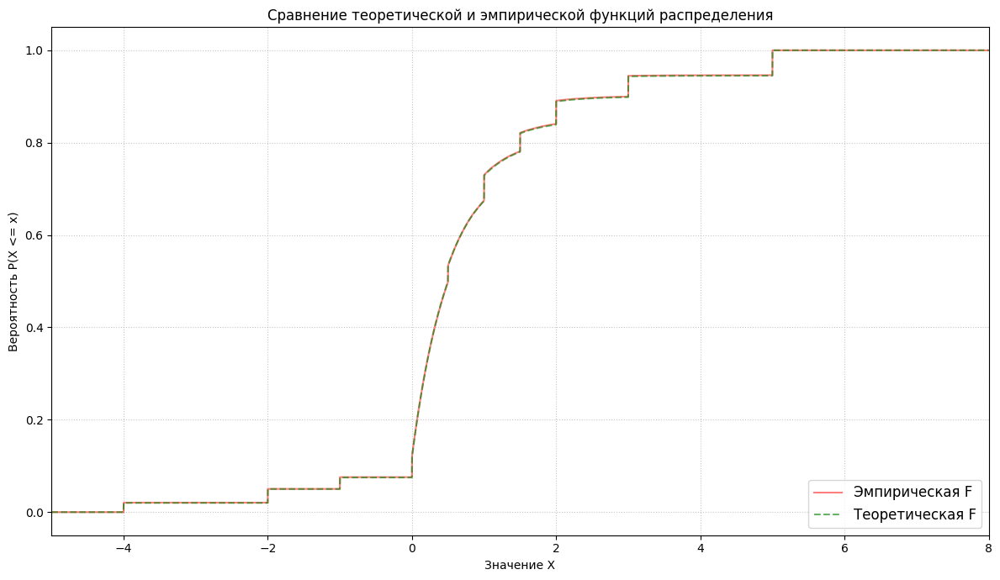

Выборка: 100000 элементов.
Максимальное отклонение эмпирической от теоретической: 0.001746


In [8]:
def theoretical_cdf(x_array):
    x = np.asarray(x_array)
    y = np.zeros_like(x, dtype=float)

    E = 0.6 * np.exp(-2 * x)

    y[x < -4] = 0.0
    y[(x >= -4) & (x < -2)] = 0.02
    y[(x >= -2) & (x < -1)] = 0.05
    y[(x >= -1) & (x < 0)] = 0.075
    y[(x >= 0) & (x < 0.5)] = 0.72 - E[(x >= 0) & (x < 0.5)]
    y[(x >= 0.5) & (x < 1.0)] = 0.755 - E[(x >= 0.5) & (x < 1.0)]
    y[(x >= 1.0) & (x < 1.5)] = 0.81 - E[(x >= 1.0) & (x < 1.5)]
    y[(x >= 1.5) & (x < 2.0)] = 0.85 - E[(x >= 1.5) & (x < 2.0)]
    y[(x >= 2.0) & (x < 3.0)] = 0.90 - E[(x >= 2.0) & (x < 3.0)]
    y[(x >= 3.0) & (x < 5.0)] = 0.945 - E[(x >= 3.0) & (x < 5.0)]
    y[x >= 5.0] = 1.0 - E[x >= 5.0]
    
    return y

n_samples = 100000
samples = generate_mixed(size=n_samples)

x_ecdf, counts = np.unique(samples, return_counts=True)
y_ecdf = np.cumsum(counts) / n_samples

x_theory = np.linspace(-5, 8, 5000)
y_theory = theoretical_cdf(x_theory)

theory_at_ecdf_points = theoretical_cdf(x_ecdf)
max_error = np.max(np.abs(y_ecdf - theory_at_ecdf_points))

plt.figure(figsize=(12, 7))
plt.step(np.concatenate([[-5], x_ecdf, [8]]), np.concatenate([[0], y_ecdf, [1]]), where='post', label='Эмпирическая F', color='red', alpha=0.5)
plt.plot(x_theory, y_theory, label='Теоретическая F', color='green', alpha = 0.6, linestyle='--')
plt.title('Сравнение теоретической и эмпирической функций распределения')
plt.xlabel('Значение X')
plt.ylabel('Вероятность P(X <= x)')
plt.xlim(-5, 8)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=12, loc='lower right')

plt.tight_layout()
plt.show()

print(f"Выборка: {n_samples} элементов.")
print(f"Максимальное отклонение эмпирической от теоретической: {max_error:.6f}")

Исходная и эмпирическая ф-и р-я на графике сливаются в одну линию. Максимальное расхождение на проверенных точках так же невелико. Реализация, значит, корректна.

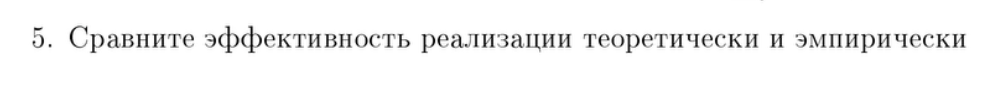

Теор. сравнение.

1. В пункте 1 для генерации одного числа требуется пройти ~15 if'ов в худшем случае (или при реализации, как здесь, через numpy - ~15 случаев с неравенствами, но которые точно все проверятся). Сложность O(K), где K - число интервалов (скачков), у нас K ~ 15.
2. В пункте 3 метод Уолкера, пользуясь предподсчетом за O(K) генерирует значения затем за O(1). Непрерывная часть также генерируется за константное время. Итого - скорость генерации одного значения составляет O(1).

Вывод - второй способ теоретически эффективнее (O(1) на запрос с предподсчетом O(K) против просто O(K) на запрос).

In [11]:
import time

n_tests = 10**6
print(f"--- Эмпирическое сравнение скорости генерации (N = {n_tests}) ---")

start_time_1 = time.perf_counter()
res1 = quantile_function(np.random.rand(n_tests))
end_time_1 = time.perf_counter()

time_method_1 = end_time_1 - start_time_1
print(f"Пункт 1 (Квантильная функция): {time_method_1:.4f} сек.")


start_time_2 = time.perf_counter()
res2 = generate_mixed(n_tests)
end_time_2 = time.perf_counter()

time_method_2 = end_time_2 - start_time_2
print(f"Пункт 3 (Смесь + Схема Уолкера): {time_method_2:.4f} сек.")

ratio = time_method_1 / time_method_2
print("-" * 60)
print(f"ВЫВОД: Реализация из Пункта 3 работает в {ratio:.1f} раз быстрее!")


--- Эмпирическое сравнение скорости генерации (N = 1000000) ---
Пункт 1 (Квантильная функция с if-условиями): 0.0570 сек.
Пункт 3 (Смесь + Схема Уолкера): 0.0177 сек.
------------------------------------------------------------
ВЫВОД: Реализация из Пункта 3 работает в 3.2 раз быстрее!
